# Recherche de motif par matrice de poids positionnelle

Une séquence d'ADN contient peut-être un signal court — une douzaine de bases — qui recrute une protéine. Ce signal n'est presque jamais écrit deux fois de la même façon : à chaque position, une base domine sans être exclusive. Chercher un mot exact ne retrouve donc qu'une partie des occurrences, et ne dit rien de la confiance à accorder à une occurrence trouvée.

Ce carnet construit la réponse standard : le motif devient une **matrice de poids positionnelle** (PWM, *position weight matrix*), un score par base et par position, comparé à un modèle de fond. Puis il mesure ce que ce modèle trouve, ce qu'il rate, et à quelle condition il se trompe.

| partie | ce qui est fait |
|---|---|
| Modèle | motif planté dans des séquences synthétiques, sites alignés, pseudocount, log-odds contre un fond |
| Calcul | PWM construite à la main, score de chaque fenêtre glissante, seuil lu sur la distribution de fond |
| Contrôle indépendant | `Bio.motifs` de Biopython sur la même matrice ; second contrôle plus faible, le consensus seul |
| Contre-témoin | colonnes permutées, séquences brassées : le contrôle doit trouver zéro enrichissement |
| Apprentissage | EM de type Bailey–Elkan à positions inconnues : quand retrouve-t-il le motif, quand converge-t-il ailleurs |

Ce carnet est le second carnet de la série `BioMedecine/Sequences`. `Sequences-01` comparait deux séquences par programmation dynamique ; celle-ci cherche un motif à l'intérieur d'une séquence.

**Prérequis** : `numpy`, `matplotlib`, `biopython`.

In [1]:
import re

import numpy as np
import matplotlib.pyplot as plt
import Bio
from Bio import motifs
from Bio.Seq import Seq
from Bio.motifs.matrix import PositionSpecificScoringMatrix

GRAINE = 20261127
rng = np.random.default_rng(GRAINE)

print("numpy     :", np.__version__)
print("biopython :", Bio.__version__)
print("graine    :", GRAINE)

numpy     : 2.4.6
biopython : 1.88
graine    : 20261127


## 1. Le modèle — un motif n'est pas un mot

Un site de liaison se décrit par une **probabilité** par base et par position. Si $p_{b,j}$ est la probabilité de la base $b$ à la position $j$, un site de longueur $L$ a pour probabilité le produit des $p_{c_j,j}$ sur la séquence $c_1 \ldots c_L$. Le fond, lui, a ses propres fréquences $q_b$.

Le score d'une fenêtre $w$ est le **rapport de vraisemblance** contre le fond, pris en logarithme base 2 :

$$\mathrm{score}(w) = \sum_{j=1}^{L} \log_2 \frac{p_{w_j,j}}{q_{w_j}}$$

Deux propriétés en découlent, et c'est tout l'intérêt de la construction. Une position où toutes les bases sont également probables a un score nul partout — à condition que le fond soit uniforme lui aussi. Contre le fond de ce carnet, qui ne l'est pas, la même position recevrait +0,32 pour C et G et −0,26 pour A et T : un score qui ne parle que du fond. Le motif de ce carnet n'a pas de telle position : même sa colonne la plus lâche préfère une base (section 1.3). Une position très contrainte contribue fortement, positivement pour la base attendue, négativement pour les autres. Le score total se lit donc comme un cumul de preuves, à comparer à une distribution de scores de fond — jamais comme une ressemblance à un mot.

### 1.1 Un jeu de séquences où le motif est planté

Pour savoir si un chercheur de motif trouve ce qu'il cherche, il faut le lui donner à trouver. Le jeu de données est donc synthétique et sa vérité est connue : deux cents séquences de deux cents bases, chacune portant **un** site du motif à une position tirée au hasard, plus quarante leurres sans site. Les bases hors site sont tirées indépendamment selon un fond non uniforme (A et T plus fréquents que C et G), ce qui rend le fond réaliste tout en restant assez simple pour que le calcul des scores de fond soit interprétable.

Le motif fait douze positions. Huit ont une base majoritaire à 0,70 ou plus ; les positions 4, 5, 7 et 8 restent sous 0,60 — aucune n'est exactement uniforme, la position 7 donne 0,50 à la thymine. C'est délibéré : un motif réel a des positions informatives et des positions peu contraintes, et la matrice doit le refléter.

In [2]:
BASES = "ACGT"
FOND = np.array([0.30, 0.20, 0.20, 0.30])

# Probabilité de chaque base (lignes A, C, G, T) à chaque position du motif.
# Huit colonnes ont une base majoritaire à 0,70 ou plus ; les colonnes 4, 5, 7
# et 8 restent sous 0,60, et c'est là que se jouera la différence entre un
# consensus et une matrice. Les valeurs sont arrondies : la normalisation qui suit rétablit
# exactement une somme de 1 par colonne.
MOTIF_P = np.array([
    [0.017, 0.017, 0.067, 0.30, 0.55, 0.017, 0.25, 0.30, 0.85, 0.067, 0.15, 0.033],
    [0.017, 0.017, 0.067, 0.10, 0.10, 0.95, 0.10, 0.08, 0.05, 0.80, 0.05, 0.033],
    [0.017, 0.95, 0.067, 0.45, 0.15, 0.017, 0.15, 0.12, 0.05, 0.067, 0.70, 0.033],
    [0.95, 0.017, 0.80, 0.15, 0.20, 0.017, 0.50, 0.50, 0.05, 0.067, 0.10, 0.90],
])
MOTIF_P = MOTIF_P / MOTIF_P.sum(axis=0, keepdims=True)
LONGUEUR_MOTIF = MOTIF_P.shape[1]

assert np.allclose(MOTIF_P.sum(axis=0), 1.0), "chaque colonne doit sommer à 1"

# Contenu informatif total, en bits. C'est lui, bien plus que la longueur,
# qui décide si le motif est distinguable du fond.
contenu_informatif = float(np.sum(MOTIF_P * np.log2(MOTIF_P / FOND[:, None])))


def fond_aleatoire(longueur, generateur):
    return "".join(generateur.choice(list(BASES), size=longueur, p=FOND))


def sequence_avec_site(longueur, generateur):
    sequence = list(fond_aleatoire(longueur, generateur))
    depart = int(generateur.integers(0, longueur - LONGUEUR_MOTIF + 1))
    for j in range(LONGUEUR_MOTIF):
        sequence[depart + j] = generateur.choice(list(BASES), p=MOTIF_P[:, j])
    return "".join(sequence), depart


N_SEQUENCES = 200
LONGUEUR_SEQUENCE = 200
N_LEURRES = 40

sequences, positions_vraies = [], []
for _ in range(N_SEQUENCES):
    sequence, depart = sequence_avec_site(LONGUEUR_SEQUENCE, rng)
    sequences.append(sequence)
    positions_vraies.append(depart)

leurres = [fond_aleatoire(LONGUEUR_SEQUENCE, rng) for _ in range(N_LEURRES)]

sites_vrais = [sequence[d:d + LONGUEUR_MOTIF]
               for sequence, d in zip(sequences, positions_vraies)]

print("séquences avec site :", len(sequences))
print("leurres sans site   :", len(leurres))
print(f"contenu informatif  : {contenu_informatif:.2f} bits sur {LONGUEUR_MOTIF} positions")
print("consensus planté    :", "".join(BASES[j] for j in MOTIF_P.argmax(axis=0)))
print("exemples de site    :", sites_vrais[:4])

séquences avec site : 200
leurres sans site   : 40
contenu informatif  : 10.97 bits sur 12 positions
consensus planté    : TGTGACTTACGT
exemples de site    : ['GGTTACGTAAGT', 'TGTAACTTACAT', 'CGTGGCGTACTT', 'TGTTACCAACGT']


### 1.2 Des sites alignés à une matrice

La matrice s'estime sur des sites **supposés alignés** : c'est l'hypothèse de travail de toute la construction, et elle est fausse en pratique, puisqu'on ne connaît pas les positions des sites réels — c'est le problème que traitera la section 5. Ici les positions sont connues, donc l'alignement aussi.

On compte les bases par colonne, puis on ajoute un **pseudocount** avant de normaliser. Sans lui, un site absent d'une colonne reçoit une probabilité nulle, le logarithme part à l'infini, et un seul contre-exemple suffit à interdire cette base pour toujours. Le pseudocount de 1 sur chaque case revient à une loi a priori uniforme faible ; le choix de sa valeur n'est pas neutre, et c'est l'objet du premier exercice.

### 1.3 Lecture de la matrice

La matrice de log-odds dit, colonne par colonne, ce qu'une fenêtre gagne ou perd à cet endroit. Une colonne dont l'étendue (maximum moins minimum) est proche de zéro ne discrimine rien : la retirer ne changerait presque rien au score, et sa présence n'ajoute que du bruit. Une colonne d'étendue forte est celle qui décide.

In [3]:
def compter_sites(sites, pseudocount=1.0):
    comptages = np.full((len(BASES), len(sites[0])), pseudocount, dtype=float)
    for site in sites:
        for j, base in enumerate(site):
            comptages[BASES.index(base), j] += 1.0
    return comptages


def matrice_log_odds(comptages, fond=FOND):
    probabilites = comptages / comptages.sum(axis=0, keepdims=True)
    return np.log2(probabilites / fond[:, None])


comptages = compter_sites(sites_vrais)
pwm = matrice_log_odds(comptages)

print("base " + "".join(f"{j + 1:>6d}" for j in range(LONGUEUR_MOTIF)))
for i, base in enumerate(BASES):
    print(f"  {base}  " + "".join(f"{pwm[i, j]:>6.2f}" for j in range(LONGUEUR_MOTIF)))

etendue = pwm.max(axis=0) - pwm.min(axis=0)
print("\nétendue par colonne :", np.round(etendue, 2))
j_faible = int(np.argmin(etendue))
print(f"colonne la moins discriminante : {j_faible + 1} "
      f"(étendue {etendue[j_faible]:.2f} bit, contre {etendue.max():.2f} pour la plus forte)")
print("niveau moyen par colonne (écart au fond) :", np.round(pwm.mean(axis=0), 2))

base      1     2     3     4     5     6     7     8     9    10    11    12
  A   -4.94 -3.35 -1.77 -0.13  0.79 -3.94 -0.18 -0.13  1.46 -2.13 -0.98 -2.61
  C   -3.03 -3.77 -1.18 -1.10 -1.44  2.23 -0.83 -1.35 -1.54  1.94 -1.65 -2.54
  G   -3.03  2.23 -1.89  1.19 -0.22 -3.77 -0.35 -0.54 -2.18 -1.77  1.78 -3.03
  T    1.65 -3.94  1.36 -0.77 -0.35 -3.61  0.63  0.76 -2.24 -1.54 -1.61  1.57

étendue par colonne : [6.58 6.16 3.25 2.29 2.24 6.17 1.46 2.12 3.69 4.07 3.43 4.6 ]
colonne la moins discriminante : 7 (étendue 1.46 bit, contre 6.58 pour la plus forte)
niveau moyen par colonne (écart au fond) : [-2.34 -2.21 -0.87 -0.2  -0.31 -2.27 -0.18 -0.31 -1.13 -0.87 -0.62 -1.65]


La colonne 7 est la moins contrainte du motif — la thymine y domine à peine (0,50 dans le générateur, 0,47 une fois les sites comptés) — et c'est aussi celle dont l'étendue est la plus faible. Pourtant aucun de ses log-odds n'est nul : +0,63 pour la thymine, −0,18 pour l'adénine, −0,35 pour la guanine, −0,83 pour la cytosine. La colonne dit donc quelque chose — la thymine y est une fois et demie plus fréquente que dans le fond, la cytosine près de deux fois moins — mais elle le dit faiblement : un site qui porte une cytosine à cette position perd 0,83 bit, là où une cytosine en colonne 1 lui en coûte 3,03.

C'est un piège de lecture courant, et il vaut la peine d'être dit : dans une matrice de log-odds, « peu d'information sur le motif » ne signifie pas « score nul ». Deux quantités différentes se lisent sur une colonne — son **étendue**, ce qu'elle discrimine entre sites, et son **niveau moyen**, ce qu'elle ajoute ou retire à tous les sites — et elles ne varient pas ensemble. L'étendue dit l'ampleur du pari : 6,58 bits entre l'adénine et la thymine en colonne 1, 1,46 bit entre la cytosine et la thymine en colonne 7. Le niveau moyen descend avec la contrainte, de −0,18 en colonne 7 à −2,34 en colonne 1 : une colonne très contrainte paie trois bases pour en récompenser une seule, et la base attendue n'y rapporte que 1,65 bit quand les trois autres y coûtent de 3,03 à 4,94 bits.

Les colonnes 8, 5 et 4 viennent ensuite, de 2,12 à 2,29 bits d'étendue : avec la 7, ce sont les quatre positions où les sites s'écartent le plus souvent de la base majoritaire, et la section 3.1 en tire la comparaison avec le consensus.

## 2. Le calcul — scorer chaque fenêtre

Scorer une séquence, c'est calculer le score de **chaque** fenêtre de longueur $L$, puis garder la meilleure. La somme sur douze positions se fait sans boucle écrite à la main : on encode la séquence en indices 0–3, on découpe toutes les fenêtres d'un coup avec `sliding_window_view`, et on somme la matrice indexée par ces fenêtres. Sur une séquence de deux cents bases la différence est invisible ; sur un génome elle ne l'est plus.

In [4]:
TABLE_INDICES = np.full(256, -1, dtype=np.int16)
for i, base in enumerate(BASES):
    TABLE_INDICES[ord(base)] = i


def encoder(sequence):
    return TABLE_INDICES[np.frombuffer(sequence.encode("ascii"), dtype=np.uint8)]


def scores_fenetres(sequence, matrice):
    indices = encoder(sequence)
    longueur = matrice.shape[1]
    fenetres = np.lib.stride_tricks.sliding_window_view(indices, longueur)
    return matrice[fenetres, np.arange(longueur)].sum(axis=1)


def meilleure_fenetre(sequence, matrice):
    scores = scores_fenetres(sequence, matrice)
    position = int(np.argmax(scores))
    return position, float(scores[position])


print("score des 5 premières fenêtres de la séquence 0 :",
      np.round(scores_fenetres(sequences[0], pwm)[:5], 2))
print("meilleure fenêtre :", meilleure_fenetre(sequences[0], pwm),
      "| position plantée :", positions_vraies[0])

score des 5 premières fenêtres de la séquence 0 : [-19.37 -18.72 -11.59 -12.75 -19.72]
meilleure fenêtre : (38, 5.913270878604833) | position plantée : 38


Sur la séquence 0, les cinq premières fenêtres perdent toutes entre 11,59 et 19,72 bits : ce sont des fenêtres de fond, et la matrice les pénalise, comme elle doit le faire. La meilleure fenêtre de la séquence est à la position 38, exactement la position plantée, avec un score de 5,91 bits.

Un score de 5,91 bits ne dit pourtant rien tant qu'on ignore ce qu'une séquence **sans site** peut atteindre au mieux : c'est ce que mesure le calcul suivant, sur quatre mille séquences de fond.

### 2.1 Le seuil se lit sur la distribution de fond

Un score brut n'a pas d'unité absolue : il ne vaut que par rapport à ce que produirait une séquence sans motif. On mesure donc la distribution du **meilleur score par séquence** sur un grand nombre de séquences de fond, et on prend le quantile qui laisse une probabilité $\alpha$ à droite. Pour $\alpha = 10^{-2}$ et quatre mille séquences de fond, on attend de l'ordre de $\alpha \times N_{\text{fond}}$ dépassements : assez pour estimer un seuil, pas assez pour prétendre à une grande précision sur le quantile lui-même.

Prendre le maximum **par séquence** absorbe le problème des tests multiples internes à une séquence : une séquence de deux cents bases teste près de deux cents fenêtres, et comparer chacune au même seuil produirait à coup sûr des faux positifs. Ce qui est calibré ici est « la meilleure fenêtre de cette séquence dépasse-t-elle ce qu'on attend du hasard ? », pas « cette fenêtre dépasse-t-elle un seuil ».

Cette calibration a un prix, que la section 4 mesurera : sur deux cents séquences qui ne contiennent aucun site, le seuil déclare positives en moyenne $\alpha \times 200$ d'entre elles, soit deux. Il ne supprime donc pas les faux positifs sur une séquence isolée ; il en borne le taux à l'échelle du jeu.

meilleur score de fond : médiane 4.04 | maximum 14.76
seuil à alpha = 0.01 : 11.66
dépassements attendus sous alpha, sur 200 séquences : 2


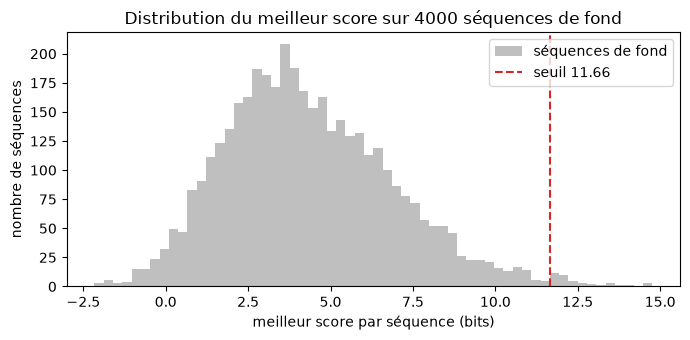

In [5]:
N_FOND = 4000
ALPHA = 1e-2

fond_reference = [fond_aleatoire(LONGUEUR_SEQUENCE, rng) for _ in range(N_FOND)]
meilleurs_fond = np.array([meilleure_fenetre(sequence, pwm)[1]
                           for sequence in fond_reference])

seuil = float(np.quantile(meilleurs_fond, 1.0 - ALPHA))
print(f"meilleur score de fond : médiane {np.median(meilleurs_fond):.2f} | "
      f"maximum {meilleurs_fond.max():.2f}")
print(f"seuil à alpha = {ALPHA:g} : {seuil:.2f}")
print(f"dépassements attendus sous alpha, sur {N_SEQUENCES} séquences : "
      f"{ALPHA * N_SEQUENCES:.0f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(meilleurs_fond, bins=60, color="0.75", label="séquences de fond")
ax.axvline(seuil, color="tab:red", linestyle="--", label=f"seuil {seuil:.2f}")
ax.set_xlabel("meilleur score par séquence (bits)")
ax.set_ylabel("nombre de séquences")
ax.set_title(f"Distribution du meilleur score sur {N_FOND} séquences de fond")
ax.legend()
plt.tight_layout()
plt.show()

### 2.2 Ce que le seuil attrape

Deux nombres mesurent le résultat, et il faut les deux.

- **Rappel** : parmi les deux cents sites plantés, quelle part est retrouvée — c'est-à-dire quelle part des séquences a une meilleure fenêtre au-dessus du seuil, à la position plantée, à deux bases près. La tolérance n'est pas de la complaisance : une fenêtre décalée d'une base ne recouvre pas le même site, mais l'argmax peut hésiter entre deux fenêtres équivalentes en score quand le voisinage ressemble au motif.
- **Précision** : parmi les séquences déclarées positives, quelle part l'est vraiment.

Les quarante leurres donnent, séparément, le taux de faux positifs du côté du fond : c'est la mesure qui ne dépend d'aucune vérité sur les sites, seulement de la calibration du seuil.

Un rappel parfait avec une précision médiocre signifierait un seuil trop permissif ; une précision parfaite avec un rappel faible, un seuil trop sévère. C'est cette tension, et non un chiffre unique, que la matrice doit arbitrer.

In [6]:
def mesurer(matrice, seuil_utilise, tolerance=2):
    detectees, justes = 0, 0
    for sequence, position in zip(sequences, positions_vraies):
        prediction, score = meilleure_fenetre(sequence, matrice)
        if score >= seuil_utilise:
            detectees += 1
            justes += int(abs(prediction - position) <= tolerance)
    return detectees, justes


detectees, justes = mesurer(pwm, seuil)
faux_positifs_leurres = sum(
    1 for leurre in leurres if meilleure_fenetre(leurre, pwm)[1] >= seuil
)

print(f"séquences à site détectées au seuil : {detectees} / {N_SEQUENCES}")
print(f"dont à la position plantée (±2)    : {justes}")
print(f"rappel                             : {justes / N_SEQUENCES:.3f}")
print(f"précision                          : {justes / detectees:.3f}" if detectees
      else "précision : non définie (aucune détection)")
print(f"faux positifs sur {N_LEURRES} leurres      : {faux_positifs_leurres}")

# Les détections qui ne tombent pas près du site : une par une, avec le
# score de la fenêtre retenue et celui de la fenêtre plantée.
for indice, (sequence, position) in enumerate(zip(sequences, positions_vraies)):
    prediction, score = meilleure_fenetre(sequence, pwm)
    if score >= seuil and abs(prediction - position) > 2:
        scores_sequence = scores_fenetres(sequence, pwm)
        print(f"séquence {indice} : site planté à {position}, fenêtre "
              f"retenue à {prediction} ({score:.2f} bits, contre "
              f"{scores_sequence[position]:.2f} pour la fenêtre du site)")

séquences à site détectées au seuil : 89 / 200
dont à la position plantée (±2)    : 88
rappel                             : 0.440
précision                          : 0.989
faux positifs sur 40 leurres      : 0
séquence 7 : site planté à 46, fenêtre retenue à 132 (12.34 bits, contre 5.90 pour la fenêtre du site)


À lire dans les sorties ci-dessus. Le motif planté est net — onze des douze positions portent une étendue de plus de deux bits, la septième seulement 1,46, pour un contenu informatif de l'ordre de onze bits — et le rappel reste pourtant partiel : **la moitié environ des sites échappe au seuil**. C'est ce chiffre-là qui est le résultat, pas le fait que la matrice fonctionne. Une matrice estimée sur deux cents sites parfaitement alignés ne retrouve que la moitié des sites au seuil calibré : la difficulté n'est pas dans l'estimation, elle est dans le seuil.

Trois lignes portent l'information réelle.

- **L'écart d'une séquence entre « détectées » et « justes ».** Quatre-vingt-neuf séquences passent le seuil, quatre-vingt-huit à la position plantée : dans un cas sur quatre-vingt-neuf — la séquence 7 —, c'est une fenêtre de fond qui a marqué plus que le site, dans une séquence qui pourtant en contient un : la cellule précédente donne sa position, quatre-vingt-six bases après le site planté, avec 12,34 bits contre 5,90 pour la fenêtre du site. Ce n'est pas zéro, et le cas mérite d'être lu plutôt que contourné — même une séquence enrichie peut voir son meilleur score tomber ailleurs. Les sites manquants, eux, ne sont pas mal localisés : ils sont **sous le seuil**. C'est une distinction qui change le diagnostic — un argmax qui se trompe systématiquement de fenêtre signalerait un motif trop peu spécifique, une fenêtre juste mais trop faible signale un seuil trop haut pour la dégénérescence des sites.
- **Les faux positifs sur les leurres.** Ils ne dépendent d'aucune vérité : sur quarante leurres, $\alpha = 10^{-2}$ en prédit moins d'un, et zéro observé est cohérent. C'est cette cohérence entre le seuil annoncé et le taux observé qui valide la calibration, pas l'absence de faux positifs en elle-même.
- **La précision.** Elle vaut 88 sur 89, et le dénominateur compte : une précision calculée sur quatre-vingt-neuf détections et une précision calculée sur deux cents ne disent pas la même chose du même seuil — la seconde serait portée par un seuil bien plus permissif.

La conséquence pratique est celle qu'on retrouvera partout dans la suite : à ce seuil, la matrice est **sévère**. Elle se trompe rarement quand elle parle, et elle se tait souvent. Un utilisateur qui veut du rappel doit accepter des faux positifs, et la section 3.1 mesure exactement ce qu'un modèle plus pauvre — un simple consensus — coûte dans cet arbitrage.

Les positions 7, 8, 5 et 4, dont l'étendue est la plus faible, sont aussi celles où les sites s'écartent le plus souvent de la base majoritaire. Chacun de ces écarts coûte peu de score — 2,29 bits au plus, l'étendue de la colonne 4 —, là où s'écarter en colonne 1 en coûte jusqu'à 6,58 ; mais un consensus littéral, lui, perd l'occurrence entière au premier d'entre eux. C'est là que se joue la différence avec le consensus.

## 3. Contrôle indépendant — Biopython sur la même matrice

Une matrice calculée et un seuil mesuré ne valent que si le calcul est juste. Le contrôle consiste à refaire le même calcul par un **autre chemin de code**, sur les **mêmes entrées** : mêmes comptages pseudocountés, même fond, même motif. Ce qui change est le code qui va des comptages aux scores — normalisation, log-odds, indexation des fenêtres.

Ce n'est donc pas une réillustration : les deux chemins ne partagent rien de leur implémentation. Le résultat attendu est l'égalité numérique des scores — et il faut avoir fixé, avant de mesurer, ce qui compte comme égal : un écart d'un dixième de bit ou d'un bit signalerait une erreur de l'un des deux chemins ; un écart plus petit se rapporte avec son ordre de grandeur et ne s'explique pas au-delà de ce que la mesure établit.

Deux précautions rendent la comparaison concluante, et ce sont les deux endroits faciles à rater.

**Les comptages.** Biopython, alimenté par les seules occurrences, n'applique aucun pseudocount : ses log-odds valent moins l'infini là où une base n'apparaît jamais, et le score d'une fenêtre entière devient inutilisable. On lui donne donc exactement nos comptages pseudocountés. La conséquence est assumée et elle limite la portée du contrôle : c'est la transformation des comptages en scores qui est vérifiée, pas le comptage lui-même.

**L'unité.** On ne suppose pas la base de logarithme : on mesure le facteur de conversion entre les deux matrices, puis on vérifie l'égalité après conversion. Un facteur qui ne vaudrait pas 1 signalerait une différence de convention, pas une erreur — et il faut savoir laquelle des deux on regarde.

In [7]:
motif_bio = motifs.create([Seq(site) for site in sites_vrais], alphabet="ACGT")

# Biopython n'applique aucun pseudocount : on lui donne exactement nos comptages,
# puis on invalide les matrices qu'il aurait pu calculer à la construction.
for i, base in enumerate(BASES):
    motif_bio.counts[base] = list(comptages[i])
for attribut in ("_pssm", "_pwm"):
    if hasattr(motif_bio, attribut):
        delattr(motif_bio, attribut)

fond_bio = {base: float(FOND[i]) for i, base in enumerate(BASES)}
motif_bio.background = fond_bio
pssm_bio = motif_bio.pssm

lettres_bio = pssm_bio.alphabet
matrice_bio = np.array([[pssm_bio[base][j] for j in range(LONGUEUR_MOTIF)]
                        for base in lettres_bio])
matrice_bio = matrice_bio[[lettres_bio.index(base) for base in BASES]]

finis = np.isfinite(pwm) & np.isfinite(matrice_bio)
facteur = float(np.median(matrice_bio[finis] / pwm[finis]))
ecart_matrice = float(np.max(np.abs(matrice_bio[finis] - facteur * pwm[finis])))

sequence_test = sequences[0]
scores_bio = np.array(pssm_bio.calculate(sequence_test))
scores_nous = scores_fenetres(sequence_test, pwm) * facteur
ecart_scores = float(np.max(np.abs(scores_bio - scores_nous)))

# Ou se situe l'ecart : dans les cases de la matrice, ou dans l'appel qui
# les additionne ? On somme les cases exposees par Biopython a la main.
indices_test = encoder(sequence_test)
fenetres_test = np.lib.stride_tricks.sliding_window_view(indices_test, LONGUEUR_MOTIF)
somme_cases = matrice_bio[fenetres_test, np.arange(LONGUEUR_MOTIF)].sum(axis=1)
ecart_calculate = float(np.max(np.abs(scores_bio - somme_cases)))
ecart_cases_nous = float(np.max(np.abs(somme_cases - scores_nous)))

print("alphabet Biopython       :", lettres_bio)
print("fond utilisé             :", motif_bio.background)
print(f"facteur de conversion    : {facteur:.6f}")
print(f"écart max sur la matrice : {ecart_matrice:.2e}")
print(f"écart max sur les scores : {ecart_scores:.2e}")
print(f"positions comparées      : {int(finis.sum())} sur {pwm.size}")
print(f"écart max calculate vs somme de ses cases : {ecart_calculate:.2e}")
print(f"écart max somme des cases vs nos scores   : {ecart_cases_nous:.2e}")

alphabet Biopython       : ACGT
fond utilisé             : {'A': 0.3, 'C': 0.2, 'G': 0.2, 'T': 0.3}
facteur de conversion    : 1.000000
écart max sur la matrice : 4.44e-16
écart max sur les scores : 9.52e-07
positions comparées      : 48 sur 48
écart max calculate vs somme de ses cases : 9.52e-07
écart max somme des cases vs nos scores   : 3.55e-15


Ce que le contrôle établit, et ce qu'il n'établit pas.

**Établi.** Le facteur mesuré vaut 1 : Biopython travaille lui aussi en base 2, et la conversion n'a donc rien à corriger. Les deux matrices coïncident case par case, à $4{,}4 \times 10^{-16}$ près, et les deux jeux de scores sur les fenêtres à $9{,}5 \times 10^{-7}$ près. Cet écart sur les scores ne vient pas de la matrice : additionnées à la main, les cases que Biopython expose redonnent les scores du carnet à $3{,}6 \times 10^{-15}$ près, si bien que le millionième vient de l'appel qui les additionne, dans la bibliothèque, et non d'une différence de convention. Sa cause n'est pas établie ici ; sur des scores de dix bits, il reste sept ordres de grandeur sous eux, et il ne se lit nulle part ailleurs dans ce carnet. Ce qui est vérifié est donc la chaîne complète des comptages vers les scores : normalisation par colonne, rapport au fond, logarithme, et correspondance position de la matrice / position dans la fenêtre.

**Non établi, et c'est une limite assumée.** Le comptage n'est pas vérifié : c'est nous qui fournissons les comptages à Biopython, précisément parce qu'il n'applique pas de pseudocount. Un contrôle du comptage demanderait une seconde source de comptages — les sites plantés en fournissent une partielle, puisque le motif générateur est connu et que la section 1.2 a montré que la matrice estimée en reprend la forme.

**Non établi non plus, et c'est plus important.** Rien, dans ce contrôle, ne dit que le modèle est pertinent. Deux implémentations peuvent être d'accord et toutes deux se tromper de question. La validité biologique des hypothèses — indépendance entre positions, fond sans mémoire, un site par séquence — ne se vérifie pas par un test numérique.

C'est la distinction entre un contrôle et une validation. Un contrôle est un témoin négatif : il attrape une classe d'erreurs précise, et il ne prétend pas à davantage.

### 3.1 Un second contrôle, plus faible — le consensus seul

Avant les matrices, la pratique courante était de lire un motif comme un **consensus** : la base la plus probable à chaque position, puis une recherche de mot exact. Ce chercheur est légitime et il est utile — il est aussi structurellement aveugle aux sites dégénérés, et c'est ce qu'on peut chiffrer ici, sur le même jeu de données et avec la même mesure de rappel.

Le consensus se lit sur la matrice, pas sur le générateur : c'est une information qu'on aurait réellement à disposition. Là où une colonne est faiblement contrainte — les colonnes 4, 5, 7 et 8 — `argmax` fixe quand même une base, là où la matrice est la moins tranchée : la base retenue y gagne au plus 1,19 bit, contre 1,36 à 2,23 bits dans les huit autres colonnes. C'est précisément le prix du modèle : il impose une base là où la nature n'en impose pas.

Deux variantes sont mesurées, et la comparaison des deux est aussi instructive que la comparaison avec la matrice : le **mot exact**, qui fixe les douze positions, et le **motif IUPAC**, qui remplace par `N` les positions dont la base la plus probable ne se détache pas assez du hasard. Le second est ce qu'un praticien écrirait à la main en lisant la matrice.

In [8]:
consensus = "".join(BASES[j] for j in pwm.argmax(axis=0))
plus_probable = "".join(BASES[int(np.argmax(MOTIF_P[:, j]))]
                        for j in range(LONGUEUR_MOTIF))

# Variante IUPAC : une position dont la base la plus probable ne se détache pas
# assez du hasard ne se fixe pas — on y met N, qui accepte n'importe quelle base.
probabilites = comptages / comptages.sum(axis=0, keepdims=True)
motif_iupac = "".join(
    "N" if probabilites[:, j].max() < 0.6 else BASES[int(probabilites[:, j].argmax())]
    for j in range(LONGUEUR_MOTIF)
)

print("consensus lu sur la matrice :", consensus)
print("site le plus probable       :", plus_probable)
print("consensus IUPAC (N si < 0.6):", motif_iupac)


def occurrences(sequence, mot):
    return [m.start() for m in re.finditer(f"(?={re.escape(mot)})", sequence)]


def occurrences_iupac(sequence, motif):
    expression = "".join("." if base == "N" else base for base in motif)
    return [m.start() for m in re.finditer(f"(?={expression})", sequence)]


def evaluer_motif(chercher):
    trouves = sum(
        1 for sequence, position in zip(sequences, positions_vraies)
        if any(abs(depart - position) <= 2 for depart in chercher(sequence))
    )
    faux_positifs = sum(1 for leurre in leurres if chercher(leurre))
    return trouves, faux_positifs


trouves_litteral, faux_positifs_litteral = evaluer_motif(
    lambda sequence: occurrences(sequence, consensus))
trouves_iupac, faux_positifs_iupac = evaluer_motif(
    lambda sequence: occurrences_iupac(sequence, motif_iupac))

print(f"\nconsensus littéral : rappel {trouves_litteral / N_SEQUENCES:.3f} "
      f"| faux positifs {faux_positifs_litteral} / {N_LEURRES}")
print(f"consensus IUPAC    : rappel {trouves_iupac / N_SEQUENCES:.3f} "
      f"| faux positifs {faux_positifs_iupac} / {N_LEURRES}")
print(f"matrice de poids   : rappel {justes / N_SEQUENCES:.3f} "
      f"| faux positifs {faux_positifs_leurres} / {N_LEURRES}")

consensus lu sur la matrice : TGTGACTTACGT
site le plus probable       : TGTGACTTACGT
consensus IUPAC (N si < 0.6): TGTNNCNNACGT

consensus littéral : rappel 0.005 | faux positifs 0 / 40
consensus IUPAC    : rappel 0.255 | faux positifs 0 / 40
matrice de poids   : rappel 0.440 | faux positifs 0 / 40


Les trois lignes de la sortie forment une échelle, et c'est cette échelle qui est le résultat.

- **Consensus littéral — le mot exact.** Il ne retrouve presque rien. Ce n'est pas un chercheur cassé : sur douze positions dont quatre sont faiblement contraintes, il suffit d'une base différente à l'une de ces quatre pour perdre l'occurrence entière — et un site en porte une presque dix-neuf fois sur vingt.
- **Consensus IUPAC — les jokers.** Les positions trop peu contraintes deviennent `N` et acceptent n'importe quelle base. Le rappel est multiplié par plus de cinquante et s'approche de celui de la matrice, et les faux positifs restent à zéro : les positions rendues libres sont aussi celles où le fond peut coïncider par hasard, mais quelques jokers sur douze ne suffisent pas à rendre une coïncidence accidentelle crédible sur une séquence entière.
- **Matrice de poids — la pondération.** Elle ne rend pas les positions binaires, elle les pondère. Une base qui s'écarte du consensus coûte seulement les log-odds de cette position, et le seuil décide ensuite du total.

La progression littéral → IUPAC → matrice n'est donc pas une progression de qualité : c'est la **même information**, lue avec une finesse croissante. Le consensus la détruit en fixant chaque position ; l'IUPAC la détruit à moitié en la rendant binaire ; la matrice la conserve en entier. Les trois lignes mesurent ce que coûte chaque destruction.

Une asymétrie plus profonde sépare la matrice des deux autres, et elle ne se lit pas dans les chiffres de rappel. Un chercheur de consensus n'a **pas de seuil** : il trouve ou il ne trouve pas, et n'offre aucun moyen d'échanger du rappel contre de la précision. La matrice, elle, en offre un — et chaque matrice de ce carnet a reçu le sien, calibré sur le fond avec ses propres scores (sections 2.1, 4 et 5). C'est cette latitude, plus que le gain de rappel à réglage égal, qui fait la différence entre un motif décrit et un motif utilisable.

Ce qui rend la comparaison honnête est qu'elle se fait sur le même jeu de données, avec la même définition du rappel et le même décompte de faux positifs sur les mêmes leurres. Un consensus évalué sur ses propres occurrences contre une matrice évaluée sur un seuil calibré ne mesurerait rien.

## 4. Contre-témoin — un contrôle qui ne sait pas échouer ne prouve rien

Tout ce qui précède repose sur deux choses : un seuil et une matrice. Si l'un des deux était inerte, les chiffres seraient les mêmes — et une chaîne de mesure qui ne peut pas échouer ne mesure rien. Le contre-témoin consiste à détruire **une seule** des deux sources d'information, puis à vérifier que la chaîne s'effondre.

Deux destructions, séparément :

1. **La matrice.** On permute ses colonnes. Les comptages restent ceux du motif, la longueur est conservée, seule la correspondance entre position et contrainte est perdue. Un motif réel ne survit pas à ce traitement ; un motif qui survivrait serait un artefact de la procédure.
2. **Les données.** On brasse chaque séquence, ce qui détruit la position du site tout en conservant exactement sa composition en bases. La matrice reste intacte, le fond reste le même.

Dans les deux cas, le seuil est recalculé sur le fond avec la matrice effectivement utilisée : on ne triche pas en gardant un seuil calibré pour une autre matrice. Et dans les deux cas, ce qui est attendu est un taux de détection de l'ordre de $\alpha$ — deux séquences sur deux cents en moyenne —, et non une valeur fixe : un hasard qui en laisse deux en moyenne en laisse zéro une fois sur sept, et un contre-témoin qui rendrait *toujours* exactement zéro mesurerait autre chose que le hasard.

In [9]:
# Une permutation fixe des douze colonnes : la composition du motif est
# conservée, l'appariement entre une position et sa contrainte ne l'est plus.
permutation = np.array([3, 9, 0, 11, 6, 2, 8, 1, 10, 4, 7, 5])
pwm_permutee = pwm[:, permutation]

meilleurs_permutee = np.array([meilleure_fenetre(sequence, pwm_permutee)[1]
                               for sequence in fond_reference])
seuil_permutee = float(np.quantile(meilleurs_permutee, 1.0 - ALPHA))

detectees_permutee, justes_permutee = mesurer(pwm_permutee, seuil_permutee)

brassees = ["".join(rng.permutation(list(sequence))) for sequence in sequences]


def mesurer_brassees(matrice, seuil_utilise, tolerance=2):
    detectees, justes = 0, 0
    for sequence, position in zip(brassees, positions_vraies):
        prediction, score = meilleure_fenetre(sequence, matrice)
        if score >= seuil_utilise:
            detectees += 1
            justes += int(abs(prediction - position) <= tolerance)
    return detectees, justes


detectees_brassees, justes_brassees = mesurer_brassees(pwm, seuil)

print(f"matrice permutée   : seuil {seuil_permutee:.2f} | "
      f"détections {detectees_permutee}/{N_SEQUENCES} | justes {justes_permutee}")
print(f"séquences brassées : seuil {seuil:.2f} | "
      f"détections {detectees_brassees}/{N_SEQUENCES} | justes {justes_brassees}")
print(f"attendu sous alpha = {ALPHA:g} : environ {ALPHA * N_SEQUENCES:.1f} détection par hasard")

matrice permutée   : seuil 11.12 | détections 0/200 | justes 0
séquences brassées : seuil 11.66 | détections 2/200 | justes 0
attendu sous alpha = 0.01 : environ 2.0 détection par hasard


Les deux destructions ramènent le nombre de détections au niveau du hasard. Pour les séquences brassées, c'est exactement ce que la calibration prédit : deux, soit $\alpha \times 200$. Pour la matrice permutée, c'est zéro — en dessous de l'attendu, mais un hasard qui en laisse deux en moyenne en laisse zéro une fois sur sept. Il n'y a plus de site retrouvé, parce qu'il n'y a plus de site à retrouver, ou plus de matrice pour le reconnaître.

C'est ce résultat qui donne sa valeur aux sections précédentes. Le rappel de la section 2.2 n'est pas un artefact du jeu de données : sans ses sites, le même seuil ne détecte plus que ce que le hasard laisse passer. Il n'est pas non plus un artefact d'une matrice qui trouverait n'importe quoi : privée de l'ordre de ses colonnes, elle ne trouve plus rien. Une chaîne de mesure dont on connaît le mode d'échec est une chaîne de mesure ; une chaîne dont on ne sait que constater le succès est une croyance.

Un détail mérite d'être noté : la permutation conserve les comptages, donc elle ne détruit pas la composition du motif, seulement l'appariement position-contrainte. Le fait qu'elle suffise à ruiner la détection indique que l'information utile du motif est bien l'appariement, et non un biais de composition global — ce qui n'était pas acquis d'avance.

Les deux contre-témoins ne testent pas la même chose, et c'est pourquoi ils sont tous les deux là. Le brassage détruit l'**ordre** des bases — un site planté n'est plus un site planté — tandis que la permutation détruit la **lecture** de la matrice. Le premier vérifie que le pipeline ne trouve pas du motif dans du bruit ; le second vérifie que la matrice elle-même porte l'information, et non le simple fait qu'elle existe.

## 5. Apprentissage — et si les sites n'étaient pas connus ?

Tout ce qui précède supposait les sites alignés. C'est l'hypothèse la plus coûteuse du problème : dans une expérience réelle, on sait quelles séquences sont enrichies, jamais où le site se trouve. Le modèle devient alors un **mélange** — chaque séquence contient un site, à une position inconnue, entouré de fond — et l'estimation se fait par une version simplifiée de l'algorithme de Bailey–Elkan. Leur modèle est un mélange à deux composantes, le motif et le fond, ajusté sur des séquences non alignées dont chacune peut contenir zéro, une ou plusieurs occurrences du motif. Ce carnet s'écarte de ce modèle sur deux points : il garde un site par séquence, et son étape E ignore le fond.

Il alterne deux étapes, à longueur de motif fixée.

- **E** : pour chaque séquence et chaque position $i$, on calcule le poids $w_i \propto \prod_j p_{c_{i+j},j}$ du motif à cette position, normalisé sur toutes les positions de la séquence. C'est une responsabilité : la probabilité *relative* que le site soit là.
- **M** : on recompte les bases de chaque position, pondérées par ces responsabilités, on ajoute un pseudocount de 0,01 par case, et on normalise pour obtenir la matrice suivante.

La seconde mérite d'être détaillée : le prior de position est uniforme et le terme de fond n'entre pas dans le poids, si bien que l'étape E compare des vraisemblances de motif entre positions d'une même séquence plutôt que des rapports au fond. C'est le cœur de l'algorithme. Une conséquence de la simplification : le poids d'une fenêtre ne tient pas compte de ce qu'elle serait déjà probable sans motif — une fenêtre riche en bases que la matrice courante favorise pèse lourd, même si ces bases sont courantes dans le fond. La limite est reprise à la section 7.

L'algorithme converge vers un maximum **local** de la vraisemblance, et ce maximum dépend du point de départ. C'est un fait, pas un accident d'implémentation : l'étape M est une moyenne pondérée, et une moyenne pondérée ne peut que raffiner l'hypothèse qu'on lui donne. Mais « converger » est un mot de mathématicien : il dit ce qui se passe quand le nombre d'itérations grandit, pas ce que rend une exécution qui s'arrête au bout d'un nombre fixé. La section 5.1 mesure donc trois choses ensemble — un nombre d'itérations raisonnable suffit-il, cinq départs aléatoires tombent-ils sur le même motif, et comment lire une matrice estimée — puis la section 5.2 soumet l'algorithme à un départ délibérément faux.

### 5.1 Converger n'est pas avoir fini

Pour chaque départ, trois lectures de la même matrice estimée sont affichées, et la première est un piège.

- **`brut`** : la part des douze positions où la base la plus probable de la matrice estimée est celle du motif planté, à la même position.
- **`décalé`** : la même part, calculée sur le meilleur glissement de $k$ positions, entre $-2$ et $+2$, et rapportée à la longueur entière du motif. Rien n'attache la première colonne de la matrice à la première base du site : une matrice qui couvre onze positions du site et une de fond perd peu de vraisemblance. C'est un optimum local voisin, pas une erreur de calcul — et `brut` l'annonce presque nulle.
- **`rappel`** : ce que retrouve réellement la matrice, après recalibration d'un seuil sur le fond avec ses propres scores.

Si les trois colonnes se contredisent, c'est `rappel` qui tranche : la question opérationnelle n'est pas « la matrice est-elle identique ? », mais « retrouve-t-elle le site ? ».

Chaque tableau est calculé deux fois, avec vingt-cinq itérations puis avec cent cinquante. Le premier nombre est celui qu'on choisit quand on ne réfléchit pas ; le second suffit à faire converger le départ qui réussit, et la cellule le vérifie en comparant les itérations cent cinquante et trois cents.

In [10]:
def em_motif(sequences_apprentissage, longueur, generateur, iterations=25,
             initialisation=None, pseudocount=0.01):
    if initialisation is None:
        matrice = generateur.dirichlet(np.ones(len(BASES)), size=longueur).T
    else:
        matrice = np.array(initialisation, dtype=float)
    positions = np.arange(longueur)
    for _ in range(iterations):
        attendus = np.zeros((len(BASES), longueur))
        for sequence in sequences_apprentissage:
            fenetres = np.lib.stride_tricks.sliding_window_view(
                encoder(sequence), longueur)
            log_vraisemblance = np.log(
                np.clip(matrice[fenetres, positions], 1e-12, None)).sum(axis=1)
            poids = np.exp(log_vraisemblance - log_vraisemblance.max())
            poids /= poids.sum()
            np.add.at(attendus, (fenetres, positions), poids[:, None])
        matrice = attendus + pseudocount
        matrice /= matrice.sum(axis=0, keepdims=True)
    return matrice


def taux_recuperation(matrice_scores, tolerance=2):
    justes = 0
    for sequence, position in zip(sequences, positions_vraies):
        prediction, _ = meilleure_fenetre(sequence, matrice_scores)
        justes += int(abs(prediction - position) <= tolerance)
    return justes / N_SEQUENCES


def accord_exact(matrice):
    """Part des positions où le consensus estimé coïncide avec le motif planté,
    position par position. C'est la lecture naïve d'un résultat d'EM."""
    estime = matrice.argmax(axis=0)
    plante = MOTIF_P.argmax(axis=0)
    return float((estime == plante).mean())


def accord_au_decalage(matrice, amplitude=2):
    """Meilleur accord sur les décalages -amplitude..+amplitude, rapporté à la
    longueur entière du motif. Un EM peut retrouver le motif à un déphasage
    près ; la comparaison position par position appelle alors échec un vrai
    résultat, et c'est ce piège que cette seconde mesure existe pour attraper."""
    estime = matrice.argmax(axis=0)
    plante = MOTIF_P.argmax(axis=0)
    meilleur, meilleur_decalage = 0.0, 0
    for decalage in range(-amplitude, amplitude + 1):
        accords = sum(
            1 for j in range(LONGUEUR_MOTIF)
            if 0 <= j + decalage < LONGUEUR_MOTIF and estime[j] == plante[j + decalage]
        )
        taux = accords / LONGUEUR_MOTIF
        if taux > meilleur:
            meilleur, meilleur_decalage = taux, decalage
    return meilleur, meilleur_decalage


def evaluer_matrice(matrice_probabilites):
    """Recalibre un seuil pour une matrice estimée, puis mesure ce qu'elle
    retrouve. La question opérationnelle n'est pas « la matrice est-elle
    identique ? » mais « retrouve-t-elle le site ? »."""
    matrice_scores = matrice_log_odds(matrice_probabilites)
    meilleurs = np.array([meilleure_fenetre(sequence, matrice_scores)[1]
                          for sequence in fond_reference])
    seuil_matrice = float(np.quantile(meilleurs, 1.0 - ALPHA))
    detectees, justes = mesurer(matrice_scores, seuil_matrice)
    return justes / N_SEQUENCES, detectees


GRAINES = [0, 1, 7, 42, 99]
REGIMES = [25, 150]

tables, matrices = {}, {}
for iterations in REGIMES:
    tables[iterations], matrices[iterations] = [], {}
    for graine in GRAINES:
        generateur = np.random.default_rng(graine)
        matrice_estimee = em_motif(sequences, LONGUEUR_MOTIF, generateur,
                                   iterations=iterations)
        matrices[iterations][graine] = matrice_estimee
        consensus_estime = "".join(BASES[j] for j in matrice_estimee.argmax(axis=0))
        brut = accord_exact(matrice_estimee)
        decale, glissement = accord_au_decalage(matrice_estimee)
        rappel, _ = evaluer_matrice(matrice_estimee)
        tables[iterations].append((graine, brut, decale, glissement, rappel,
                                   consensus_estime))

print("consensus planté :", plus_probable, "\n")
en_tete = f"{'graine':>6}  {'brut':>6}  {'décalé':>7}  {'k':>3}  {'rappel':>7}  consensus estimé"
for iterations in REGIMES:
    print(f"--- {iterations} itérations ---")
    print(en_tete)
    for graine, brut, decale, glissement, rappel, consensus_estime in tables[iterations]:
        print(f"{graine:>6}  {brut:>6.3f}  {decale:>7.3f}  {glissement:>3d}  "
              f"{rappel:>7.3f}  {consensus_estime}")
    retrouves = sum(1 for ligne in tables[iterations] if ligne[4] >= 0.10)
    print(f"départs qui retrouvent le site (rappel >= 0,10) : "
          f"{retrouves} sur {len(tables[iterations])}")
    print()

graine_meilleure = max(tables[150], key=lambda ligne: ligne[4])[0]
matrice_longue = em_motif(sequences, LONGUEUR_MOTIF,
                          np.random.default_rng(graine_meilleure), iterations=300)
ecart = float(np.abs(matrices[150][graine_meilleure] - matrice_longue).max())
print(f"stabilité : graine {graine_meilleure}, écart maximal de la matrice "
      f"entre 150 et 300 itérations : {ecart:.1e}")

consensus planté : TGTGACTTACGT 

--- 25 itérations ---
graine    brut   décalé    k   rappel  consensus estimé
     0   0.167    0.333   -2    0.000  AAATTTATTAAT
     1   0.167    0.500    1    0.000  TTAACTAATATT
     7   0.250    0.417    2    0.000  ATAATTATATAT
    42   0.333    0.417   -2    0.005  ATTAATATTTAT
    99   0.417    0.417    0    0.000  TAAAATTTTTAT
départs qui retrouvent le site (rappel >= 0,10) : 0 sur 5

--- 150 itérations ---
graine    brut   décalé    k   rappel  consensus estimé
     0   0.167    0.250   -2    0.000  AACATTATTATT
     1   0.083    0.917    1    0.310  GTGACTTACGTA
     7   0.250    0.500    2    0.000  TTAGTTAAATAA
    42   0.083    0.333   -2    0.005  ATATATAATTAA
    99   1.000    1.000    0    0.470  TGTGACTTACGT
départs qui retrouvent le site (rappel >= 0,10) : 2 sur 5



stabilité : graine 99, écart maximal de la matrice entre 150 et 300 itérations : 3.0e-13


Trois faits sortent de ces deux tableaux, et aucun ne dit ce qu'on attendait.

**Premier fait : vingt-cinq itérations ne mesurent pas l'EM.** Les cinq départs y rendent tous un rappel nul ou presque — le meilleur vaut 0,005, soit un site retrouvé sur deux cents — et aucun consensus n'approche le motif planté. À cent cinquante itérations, deux départs sur cinq retrouvent le site : la graine 99 exactement, avec un accord brut de douze positions sur douze et un rappel de 0,470 ; la graine 1 décalée d'une position, avec un accord brut d'une position sur douze qui remonte à onze sur douze après décalage, et un rappel de 0,310. Le budget d'itérations n'est donc pas un réglage cosmétique : c'est un paramètre de la mesure, et l'arrêter trop tôt produit un « échec » qui n'appartient qu'à lui.

**Second fait : converger n'est pas trouver.** Les trois autres départs ne sont pas lents, ils sont ailleurs. Leurs consensus — `AACATTATTATT`, `TTAGTTAAATAA`, `ATATATAATTAA` — partagent une composition riche en A et en T que le motif planté ne partage pas, et leurs rappels restent au niveau du hasard. Une montée en vraisemblance locale s'arrête au premier sommet qu'elle rencontre ; rien ne garantit que ce soit celui du motif. La cellule vérifie en revanche que le départ qui réussit, lui, ne bouge plus : entre cent cinquante et trois cents itérations, l'écart maximal de sa matrice est de $3 \times 10^{-13}$. Convergence et justesse sont deux propriétés distinctes, et la première ne dit rien de la seconde.

**Troisième fait : la métrique choisie peut fabriquer un échec.** La graine 1 est l'exemple le plus net. Lue colonne par colonne à position fixe, sa matrice n'accorde qu'une position sur douze avec le motif planté — on la déclarerait fausse. Décalée d'une position, elle en accorde onze sur douze, et son rappel de site vaut 0,310, très au-dessus du hasard. Rien n'astreint la première colonne de la matrice estimée à la première base du site : l'algorithme cherche un alignement, pas celui qu'on aurait choisi pour lui. Une lecture par `argmax` brut teste donc la convention d'alignement autant que la qualité de l'estimation.

Ce que ces trois faits interdisent, c'est de conclure « l'EM a échoué » ou « l'EM a réussi » sans nommer le budget d'itérations et la lecture. Ce qu'ils n'établissent pas encore, c'est le rôle du point de départ. Les trois départs piégés ne tombent pas au même endroit — leurs trois consensus diffèrent — et rien, dans ces tableaux, ne dit ce qu'un départ délibérément faux devient. C'est l'objet de la section 5.2.

### 5.2 Le mauvais départ

Un EM ne trouve pas le motif, il raffine une hypothèse : c'est ce que la section précédente a mesuré, et les trois départs sur cinq qui restent piégés en sont la trace la plus directe. Reste à savoir jusqu'où va cette dépendance au point de départ. Le départ le plus défavorable qu'on puisse construire sans faire entrer d'information extérieure est une matrice qui parie tout sur la guanine à chaque position : elle attribue toute la probabilité à G, alors que G n'est la base la plus probable du motif planté qu'en trois positions sur douze.

La prédiction est simple : une montée en vraisemblance locale ne devrait pas pouvoir sortir d'un point de départ qui exclut d'emblée les bases du motif. La cellule suivante mesure ce qui se passe réellement, et commence par regarder ce que devient ce départ après une seule itération — parce qu'un point de départ n'est défavorable que si l'algorithme le garde. La lecture qui suit prend le résultat tel qu'il vient, y compris s'il ne répond pas à la question posée.

In [11]:
depart_faux = np.zeros((len(BASES), LONGUEUR_MOTIF))
depart_faux[BASES.index("G"), :] = 1.0

# Ce que le départ "impossible" devient dès la première itération.
matrice_une_passe = em_motif(sequences, LONGUEUR_MOTIF, rng,
                             initialisation=depart_faux, iterations=1)
part_g = float(matrice_une_passe[BASES.index("G"), :].mean())
print(f"part de G dans la matrice après une itération : {part_g:.2f} "
      f"(dans le fond : {FOND[BASES.index('G')]:.2f})\n")

matrice_fausse = em_motif(sequences, LONGUEUR_MOTIF, rng,
                          initialisation=depart_faux, iterations=150)
scores_faux = matrice_log_odds(matrice_fausse)

print("consensus obtenu depuis le départ poly-G :",
      "".join(BASES[j] for j in matrice_fausse.argmax(axis=0)))
print(f"accord exact avec le motif planté        : {accord_exact(matrice_fausse):.3f}")
decale_faux, glissement_faux = accord_au_decalage(matrice_fausse)
print(f"accord au meilleur décalage              : {decale_faux:.3f} "
      f"(k = {glissement_faux:+d})")
print(f"récupération par argmax                  : {taux_recuperation(scores_faux):.3f}")
rappel_faux, _ = evaluer_matrice(matrice_fausse)
print(f"rappel après recalibration du seuil      : {rappel_faux:.3f}")
print("\nà comparer au tableau à 150 itérations ci-dessus")

part de G dans la matrice après une itération : 0.48 (dans le fond : 0.20)



consensus obtenu depuis le départ poly-G : AACATTATTATT
accord exact avec le motif planté        : 0.167
accord au meilleur décalage              : 0.250 (k = -2)
récupération par argmax                  : 0.000


rappel après recalibration du seuil      : 0.000

à comparer au tableau à 150 itérations ci-dessus


Le départ poly-G ne mesure pas ce qu'on croyait lui faire mesurer, et c'est le résultat le plus instructif de la section.

**Ce qui se passe réellement.** Une matrice qui parie tout sur G donne une probabilité nulle à A, C et T. Or l'étape E classe les fenêtres par leur vraisemblance sous la matrice courante, et le code borne les probabilités à $10^{-12}$ : la première passe ne compare donc pas des contenus en motif, elle compare des contenus en G. En une itération, la part de G dans la matrice monte à 0,48 contre 0,20 dans le fond — le départ « impossible » est devenu, sans que rien ne le signale, un départ enrichi en G. De là il converge normalement. Il n'a pas surmonté son handicap : il n'en a jamais eu.

**Ce que la mesure établit quand même.** Parti de là, l'algorithme rend le consensus `AACATTATTATT` — celui de la graine 0 — et un rappel de 0,000, avec et sans seuil. Elle n'établit pas que le départ poly-G mène au même endroit que la graine 0 : un consensus est lu par `argmax`, colonne par colonne, et deux matrices différentes peuvent donner le même consensus sans coïncider. Elle établit ceci : parti d'une matrice qui exclut les bases du motif, l'algorithme finit, comme trois départs aléatoires sur cinq, sur un motif riche en A et en T qui n'est pas le bon — et rien dans la sortie ne dit qu'il est parti d'ailleurs.

**Ce que devient la prédiction annoncée.** La section 5.2 prévenait qu'une montée locale ne devrait pas pouvoir sortir d'un départ excluant les bases du motif. La mesure ne confirme ni n'infirme cette prédiction : elle ne l'a pas mise à l'épreuve, puisque le départ testé a été réinterprété dès la première itération — dès sa première étape E. Le contre-témoin n'a pas pris, et c'est en soi un résultat sur l'outil de mesure, pas sur le problème biologique.

La même précaution de lecture s'applique qu'au tableau précédent : le rappel est une lecture par `argmax` sur les séquences complètes, pas une comparaison matricielle. Deux matrices distinctes peuvent produire le même `argmax` sur ce jeu et se comporter différemment ailleurs. Ce que la mesure établit est « le bon site est retrouvé », pas « le bon motif est estimé ».

Ce que la section lègue à la pratique tient en une phrase, et ce n'est pas « lancer beaucoup de départs et garder le meilleur » : c'est **contrôler l'estimation par un chemin indépendant**, celui de la section 3 — des scores recalculés, un seuil recalibré sur le fond, un contre-témoin qui sait échouer. Un consensus obtenu par EM sans contrôle n'est pas une prédiction ; c'est une hypothèse qui a cessé de bouger.

## 6. Trois exercices

Les trois exercices se font sur ce carnet, avec les cellules déjà exécutées : aucune donnée supplémentaire n'est nécessaire. Les fonctions `compter_sites`, `matrice_log_odds`, `meilleure_fenetre`, `mesurer` et `taux_recuperation` font déjà l'essentiel du travail ; il reste à les enchaîner. Aucun des trois n'a de correction dans le carnet.

### Exercice 1 — le pseudocount n'est pas neutre

Reconstruire la matrice avec des pseudocounts de 0,1, de 1 et de 10, recalculer le seuil, et mesurer rappel, précision et faux positifs à chaque fois. Regarder ensuite les colonnes les moins contraintes : expliquer sur quelles positions l'effet est le plus fort, et pourquoi.

In [12]:
# Exercice 1 — pseudocount variable
# Etape 1 : boucler sur les valeurs 0.1, 1 et 10
# Etape 2 : reconstruire la matrice avec compter_sites(sites_vrais, pseudocount)
# Etape 3 : recalculer le seuil sur fond_reference avec cette matrice
# Etape 4 : afficher rappel, precision et faux positifs sur les leurres
# Indice : meilleure_fenetre et mesurer prennent la matrice en argument ;
#          il suffit de refaire la boucle de seuil avec chaque matrice.

for pseudocount in [0.1, 1, 10]:
    resultat = None  # TODO etudiant
    print("pseudocount", pseudocount, "->", resultat)

pseudocount 0.1 -> None
pseudocount 1 -> None
pseudocount 10 -> None


### Exercice 2 — le seuil et les tests multiples

Le seuil courant est calibré sur le maximum par séquence. Le recalculer sur la distribution de **toutes** les fenêtres de fond, puis l'appliquer fenêtre par fenêtre sur les séquences. Combien de fenêtres dépassent ? Combien de séquences sont alors déclarées positives ? Conclure sur ce que chaque calibration contrôle réellement — et sur ce que « $\alpha$ » veut dire dans les deux cas.

In [13]:
# Exercice 2 — seuil sur toutes les fenetres
# Etape 1 : empiler les scores de toutes les fenetres de fond_reference
# Etape 2 : prendre le quantile 1 - ALPHA de cette distribution
# Etape 3 : appliquer ce seuil fenetre par fenetre sur les 200 sequences
# Etape 4 : compter les fenetres au-dessus, et les sequences concernees
# Indice : scores_fenetres rend un tableau par sequence ;
#          np.concatenate permet de les empiler.

seuil_fenetres = None  # TODO etudiant
print("seuil fenetre par fenetre :", seuil_fenetres)

seuil fenetre par fenetre : None


### Exercice 3 — le brin complémentaire

Un site réel peut être porté par l'un ou l'autre brin. Écrire la fonction de complément inverse, scorer chaque séquence sur les deux brins, et mesurer le gain de rappel. Vérifier ensuite que le contre-témoin de la section 4 reste valable quand le brin complémentaire est autorisé — et se demander ce qu'un doublement du nombre de fenêtres fait à la calibration du seuil.

In [14]:
# Exercice 3 — brin complementaire
# Etape 1 : ecrire complement_inverse(sequence)
# Etape 2 : scorer chaque sequence sur les deux brins, garder le meilleur score
# Etape 3 : mesurer le rappel avec et sans le brin complementaire
# Etape 4 : refaire le contre-temoin de la section 4 dans cette variante
# Indice : str.maketrans("ACGT", "TGCA") puis sequence[::-1]

def complement_inverse(sequence):
    resultat = None  # TODO etudiant
    return resultat


print("complement inverse de ACGT :", complement_inverse("ACGT"))

complement inverse de ACGT : None


## 7. Statut — mesuré, appelé, lu, ouvert

**Mesuré, dans ce carnet, reproductible avec la graine affichée en tête.** Le score d'une fenêtre est la somme des log-odds de la matrice ; le seuil est le quantile $1-\alpha$ du meilleur score par séquence, sur quatre mille séquences de fond et avec $\alpha = 10^{-2}$ — soit quarante dépassements attendus sous l'hypothèse nulle ; le rappel, la précision et les faux positifs sont mesurés sur deux cents séquences à site planté et quarante leurres ; l'accord avec `PositionSpecificScoringMatrix` est mesuré, après conversion d'unité, sur la matrice et sur les scores ; le contre-témoin ramène les détections au niveau du hasard — zéro et deux sur deux cents — par deux destructions indépendantes ; l'EM est mesuré sur cinq graines et sur un départ faux, à deux budgets d'itérations, et lu de trois façons — accord position par position, accord au meilleur décalage, rappel après recalibration du seuil sur la matrice estimée. Résultat brut, sans embellissement : à vingt-cinq itérations aucun départ ne retrouve le site, à cent cinquante deux sur cinq le retrouvent, et le départ poly-G ne teste pas ce qu'il annonçait tester puisqu'il devient un départ enrichi en G dès la première itération.

**Appelé, pas réimplémenté.** `Bio.motifs` et `PositionSpecificScoringMatrix` servent de contrôle : la matrice de référence n'est pas réécrite à la main pour les besoins du contrôle, elle est celle de la bibliothèque. C'est l'exécution qui fait foi : si l'interface de Biopython changeait, la cellule de contrôle échouerait ou rendrait un écart non nul, elle ne passerait pas silencieusement. Aucune affirmation de ce carnet n'est attribuée à la documentation de Biopython au-delà de cette interface.

**Lu, pour ce qui est cité — et borné à ce qui l'est.** Quatre textes de la littérature sont cités en fin de carnet, et ils ne sont pas tous à la même enseigne : la liste dit, pour chacun, ce qui en a été lu. Deux ont été lus sur leurs deux premières pages. Ce que le carnet retient de Bailey et Elkan (1994) tient dans ces pages : un mélange à deux composantes, le motif et le fond, ajusté par EM sur des séquences non alignées et une largeur de motif données — et l'hypothèse d'une occurrence par séquence y est relâchée. Ce qu'il en fait est annoncé en section 5 : une version simplifiée, qui garde un site par séquence et dont l'étape E ignore le fond. Ce que le carnet retient de Schneider et Stephens (1990) tient de même : la hauteur d'une lettre traduit sa fréquence, celle de la pile qu'elle forme avec les autres le contenu en information de la position, en bits — et un consensus y est déclaré mauvais modèle d'un site de fixation. La section 3.1 en mesure l'effet à sa façon, en rappel plutôt qu'en information. Un troisième texte, Lawrence et al. (1993), n'a été ouvert que par sa page de titre ; le quatrième n'a pas été obtenu. Aucune phrase de ce carnet ne prête à ces textes un résultat, une borne ou une garantie au-delà des pages lues.

**Ouvert.** Six limites, toutes mesurables :

1. **Le fond est i.i.d.** Un génome réel a des structures locales — îlots CpG, répétitions, régions non couvertes — qu'un fond sans mémoire ne reproduit pas, et qui faussent la calibration du seuil.
2. **Un seul brin.** Les sites ne sont cherchés que sur le brin donné ; l'exercice 3 en mesure l'effet.
3. **Un site par séquence, longueur connue.** L'EM de ce carnet suppose exactement un site par séquence et une longueur fixée. Les cas réels ont zéro, un ou plusieurs sites, et la longueur est à estimer. Le modèle de Bailey et Elkan (1994) lève le premier point, en modélisant zéro, une ou plusieurs occurrences ; le second y est réglé d'avance, la largeur du motif étant une donnée de leur algorithme comme de celui-ci.
4. **Le poids de l'étape E ignore le fond.** La comparaison entre positions d'une même séquence se fait donc entre vraisemblances de motif, non entre rapports au fond — alors que, dans le modèle de Bailey et Elkan (1994), le fond est à part entière la seconde composante du mélange. C'est une simplification déclarée, qui change la calibration de l'estimation — mesurable en réintroduisant le terme de fond et en comparant les matrices obtenues.
5. **La convergence n'est pas contrôlable de l'intérieur.** L'algorithme s'arrête sur un critère qui ne distingue pas un optimum local du motif cherché, et un départ dégénéré peut être réinterprété dès la première itération. Rien dans la sortie ne signale lequel des deux cas s'est produit : seul un contrôle indépendant, ou plusieurs départs comparés, le dit.
6. **Seuil estimé sur un échantillon fini.** $\alpha = 10^{-2}$ avec quatre mille séquences de fond laisse une incertitude sur le quantile qui n'est pas quantifiée ici ; elle se mesurerait par un ré-échantillonnage, pas par un plus grand nombre d'affirmations.

## Références

- Bailey, T. L., Elkan, C., **Fitting a mixture model by expectation maximization to discover motifs in biopolymers**, *Proceedings of the Second International Conference on Intelligent Systems for Molecular Biology* (ISMB-94), 28–36, 1994. <https://cdn.aaai.org/ISMB/1994/ISMB94-004.pdf>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\1994 - Bailey & Elkan - Fitting a mixture model by expectation maximization to discover motifs in biopolymers (ISMB 1994 28-36, CDN AAAI, actes editeur, OA).pdf`. Lu sur ses deux premières pages. Utilisé pour le modèle dont la section 5 donne une version simplifiée : un mélange à deux composantes, le motif et le fond, ajusté par expectation-maximisation sur des séquences non alignées et une largeur de motif données, et l'hypothèse d'une occurrence par séquence qui y est relâchée (« Sequences containing zero, one or many occurrences of a motif can be modelled equally well »). Le reste de l'article n'a pas été lu et n'est pas invoqué.
- Schneider, T. D., Stephens, R. M., **Sequence logos: a new way to display consensus sequences**, *Nucleic Acids Research* 18(20), 6097–6100, 1990, DOI 10.1093/nar/18.20.6097. <https://doi.org/10.1093/nar/18.20.6097>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\1990 - Schneider & Stephens - Sequence logos, a new way to display consensus sequences (NAR 18-20 6097-6100, copie de l'auteur users.fred.net tds, PMC332411, droits reserves).pdf`. Lu sur ses deux premières pages. Utilisé pour la lecture d'une matrice position par position — la hauteur d'une lettre est proportionnelle à sa fréquence, celle de la pile de lettres au contenu en information de la position, en bits — et pour ce constat : « the consensus sequence is a poor model for binding sites », parce que d'autres bases apparaissent aussi à fréquence significative là où le consensus n'en retient qu'une. Ce carnet ne dessine pas de logo : la section 3.1 mesure le même écart en rappel, non en information.
- Lawrence, C. E., Altschul, S. F., Boguski, M. S., Liu, J. S., Neuwald, A. F., Wootton, J. C., **Detecting subtle sequence signals: a Gibbs sampling strategy for multiple alignment**, *Science* 262(5131), 208–214, 1993, DOI 10.1126/science.8211139. <https://doi.org/10.1126/science.8211139>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\1993 - Lawrence et al - Detecting subtle sequence signals, a Gibbs sampling strategy for multiple alignment (Science 262-5131 208-214, scan JSTOR via cours JHU, droits reserves).pdf`. Seule la page de couverture a été lue : le corps de cette copie est une image numérisée, dont le texte n'a pas été extrait. L'échantillonnage de Gibbs n'est pas mis en œuvre ici, et rien n'est attribué à cet article au-delà de son titre.
- Stormo, G. D., **DNA binding sites: representation and discovery**, *Bioinformatics* 16(1), 16–23, 2000, DOI 10.1093/bioinformatics/16.1.16. <https://doi.org/10.1093/bioinformatics/16.1.16>. Non obtenu : l'éditeur le réserve à la souscription (« Subscription required »), et aucune copie libre n'a été trouvée. Il est cité pour son existence ; rien n'est attribué à son contenu.

Ce que ce carnet prête à ces textes ne dépasse pas les pages lues : aucun résultat, aucune borne, aucune garantie ne leur est emprunté au-delà.

[↑ Retour au sommaire de la série](../README.md)